# 02 — mT5-small fine-tuning

In [1]:
import os, time, json, gc
from pathlib import Path
os.environ["TF_USE_LEGACY_KERAS"] = "1"          # Hugging Face TF models need Keras 2 (tf-keras)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np, pandas as pd, tensorflow as tf, sacrebleu
import tf_keras as keras
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, TFMT5ForConditionalGeneration

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)      # must come first

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", gpus)

I0000 00:00:1793530915.703085    2629 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793530918.038271    2629 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/oxy/runningtensorflow/tf-gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load the shared split + evaluation helper

In [2]:
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
train  = pd.read_csv("data/train.csv",  keep_default_na=False)
val    = pd.read_csv("data/val.csv",    keep_default_na=False)
test   = pd.read_csv("data/test.csv",   keep_default_na=False)
probes = pd.read_csv("data/probes.csv", keep_default_na=False)
print("train/val/test:", len(train), len(val), len(test))

def reset_gpu_peak():
    try: tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception: pass

def gpu_peak_mb():
    try: return round(tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20)
    except Exception: return None

def evaluate(name, translate, **info):
    """Translate the SAME test set (greedy, batch size 1), then save BLEU / chrF / timing / probes."""
    translate(test.french.iloc[0])                                   # warm-up, not timed
    t0 = time.perf_counter()
    preds = [translate(s) for s in test.french]
    secs = time.perf_counter() - t0
    refs = test.english.tolist()
    res = dict(model=name,
               bleu=sacrebleu.corpus_bleu(preds, [refs]).score,
               chrf=sacrebleu.corpus_chrf(preds, [refs]).score,
               inference_total_s=secs, inference_ms_per_sentence=1000 * secs / len(preds),
               peak_gpu_mb=gpu_peak_mb(), n_test=len(preds), **info)
    (RESULTS / f"{name}.json").write_text(json.dumps(res, indent=2))
    out = pd.DataFrame(dict(french=test.french, reference=refs, prediction=preds))
    out.to_csv(RESULTS / f"{name}_predictions.csv", index=False)
    probes.assign(translation=[translate(s) for s in probes.french]).to_csv(RESULTS / f"{name}_probes.csv", index=False)
    return res, out

train/val/test: 30000 500 500


## 2. Tokenise with the original mT5 tokenizer (fixed length so TensorFlow never re-compiles)

In [3]:
MODEL_ID = "google/mt5-small"
PREFIX, MAX_TOK, BATCH, EPOCHS, LR = "translate French to English: ", 48, 16, 3, 3e-4
tok = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=False)

def encode(frame):                                   # original mT5 token ids; labels padded with 0 for now
    x = tok([PREFIX + s for s in frame.french], max_length=MAX_TOK, truncation=True, padding="max_length", return_tensors="np")
    y = tok(text_target=frame.english.tolist(), max_length=MAX_TOK, truncation=True, padding="max_length", return_tensors="np")["input_ids"]
    return {"input_ids": x["input_ids"], "attention_mask": x["attention_mask"], "labels": y}

enc = {name: encode(frame) for name, frame in [("train", train), ("val", val), ("test", test)]}
print("longest test source (tokens):", int(enc["test"]["attention_mask"].sum(1).max()), "| limit:", MAX_TOK)

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


longest test source (tokens): 38 | limit: 48


## 3. Trim the vocabulary and build the model

In [4]:
# which of the 250k vocabulary entries do we need?
used = {0, 1, 2}                                                     # pad, eos, unk
for name in ["train", "val"]:
    used |= set(np.unique(enc[name]["input_ids"]).tolist()) | set(np.unique(enc[name]["labels"]).tolist())
used |= set(np.unique(enc["test"]["input_ids"]).tolist())            # test SOURCE side only (references are never used)
used |= {i for ids in tok([PREFIX + s for s in probes.french])["input_ids"] for i in ids}
keep = np.array(sorted(used))                                        # new id = position in this list; 0, 1, 2 stay 0, 1, 2

# 1) full pretrained model on the CPU (RAM), never on the GPU
with tf.device("/CPU:0"):
    full = TFMT5ForConditionalGeneration.from_pretrained(MODEL_ID)
V, full_params = full.config.vocab_size, full.count_params()

# 2) small model with the trimmed vocabulary, created directly on the GPU
cfg = type(full.config).from_dict({**full.config.to_dict(), "vocab_size": len(keep)})
model = TFMT5ForConditionalGeneration(cfg)
model(input_ids=tf.constant([[3, 1]]), decoder_input_ids=tf.constant([[0]]))      # builds the weights

# 3) copy the pretrained numbers (vocabulary rows/columns are sliced, everything else is copied as is)
for new_w, old_w in zip(model.weights, full.weights):
    a = old_w.numpy()
    if a.shape[0] == V: a = a[keep]                              # input embedding rows
    elif a.ndim == 2 and a.shape[1] == V: a = a[:, keep]         # output head columns
    assert tuple(a.shape) == tuple(new_w.shape), new_w.name
    new_w.assign(a)
del full; gc.collect()

old2new = np.full(V, tok.unk_token_id, dtype=np.int32)           # words we dropped become <unk>
old2new[keep] = np.arange(len(keep))
total = model.count_params()
trained = int(sum(np.prod(v.shape) for v in model.trainable_variables))
print(f"vocabulary: {V:,} -> {len(keep):,} | parameters: {full_params:,} -> {total:,} | fine-tuned: {trained:,}")

def remap(e):
    labels = old2new[e["labels"]]
    return {"input_ids": old2new[e["input_ids"]], "attention_mask": e["attention_mask"],
            "labels": np.where(e["labels"] == 0, -100, labels)}          # -100 = ignored by the loss

train_ds = tf.data.Dataset.from_tensor_slices(remap(enc["train"])).shuffle(10000, seed=SEED).batch(BATCH).prefetch(2)
val_ds = tf.data.Dataset.from_tensor_slices(remap(enc["val"])).batch(BATCH).prefetch(2)

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
/home/oxy/runningtensorflow/tf-gpu/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All model checkpoint layers were used when initializing TFMT5ForConditionalGeneration.

All the layers of TFMT5ForConditionalGeneration were initialized from the model checkpoint at google/mt5-small.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFMT5ForConditionalGeneration for predictions without further training.


vocabulary: 250,112 -> 13,028 | parameters: 300,176,768 -> 57,402,752 | fine-tuned: 57,402,752


## 4. Fine-tune all weights (Hugging Face computes the loss internally)

Epoch 1/3
1875/1875 - 1080s - loss: 3.8806 - val_loss: 1.6496 - 1080s/epoch - 576ms/step
Epoch 2/3
1875/1875 - 1149s - loss: 2.1426 - val_loss: 1.3161 - 1149s/epoch - 613ms/step
Epoch 3/3
1875/1875 - 1095s - loss: 1.6645 - val_loss: 1.1266 - 1095s/epoch - 584ms/step
fine-tuning time: 55.4 min


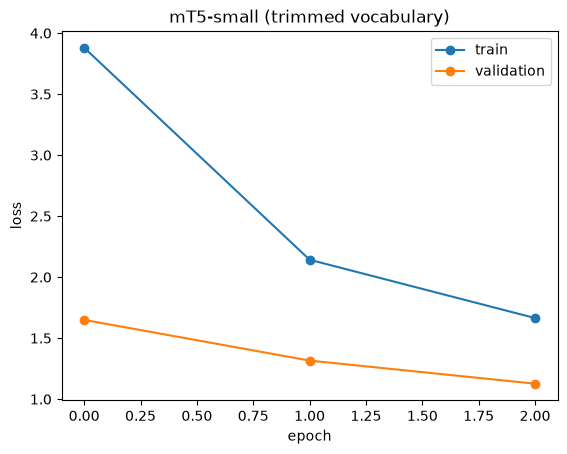

In [5]:
model.compile(optimizer=keras.optimizers.Adam(LR))
reset_gpu_peak()
t0 = time.perf_counter()
hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2)
train_seconds = time.perf_counter() - t0
print(f"fine-tuning time: {train_seconds/60:.1f} min")

plt.plot(hist.history["loss"], marker="o", label="train"); plt.plot(hist.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("mT5-small (trimmed vocabulary)"); plt.savefig("results/mt5_loss.png", dpi=120)
plt.show()

## 5. Greedy translation + evaluation on the shared test set

In [6]:
def translate(text):
    e = tok(PREFIX + text, return_tensors="np")
    ids = model.generate(input_ids=old2new[e["input_ids"]], attention_mask=e["attention_mask"],
                         max_new_tokens=MAX_TOK, num_beams=1, do_sample=False)
    return tok.decode(keep[ids[0].numpy()], skip_special_tokens=True).strip()     # new ids -> original mT5 ids -> text

print(translate("Où est la gare la plus proche ?"))
res, out = evaluate("mt5", translate,
                    architecture="encoder-decoder", adaptation="full fine-tuning (vocabulary trimmed to the task)",
                    params_total=total, params_trained=trained, train_seconds=train_seconds,
                    epochs=EPOCHS, model_id=MODEL_ID, original_params=full_params)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in res.items()})
out.head(10)

Where's the station the nearest?
{'model': 'mt5', 'bleu': 32.97, 'chrf': 51.51, 'inference_total_s': 894.31, 'inference_ms_per_sentence': 1788.62, 'peak_gpu_mb': 1488, 'n_test': 500, 'architecture': 'encoder-decoder', 'adaptation': 'full fine-tuning (vocabulary trimmed to the task)', 'params_total': 57402752, 'params_trained': 57402752, 'train_seconds': 3323.31, 'epochs': 3, 'model_id': 'google/mt5-small', 'original_params': 300176768}


,french,reference,prediction
0,Je ne connais personne de ce nom.,I don't know anyone by that name.,I don't know any name of that name.
1,Je voulais changer.,I wanted to change.,I wanted to change.
2,C'est le casier de Tom.,This is Tom's locker.,It's Tom's castle.
3,Je n'aime pas cet appareil photo.,I don't like this camera.,I don't like this camera.
4,Nous n'embauchons plus personne.,We're not hiring anymore.,We don't have anybody.
5,Ne vous laissez pas bercer par une illusion de...,Don't be lulled into a false sense of security.,Don't let you leave a threat of security.
6,Notre invité nous attend en bas.,Our guest is waiting for us downstairs.,Our invited us to wait in the base.
7,Avez-vous passé un bel été ?,Did you have a good summer?,Do you have a wonderful summer?
8,"En cas d'urgence, alerte la police.","In case of emergency, call the police.","When emergency, alert the police."
9,Sainte Anne a renoncé à sa présidence.,Santa Ana stepped down as president.,Mary rejected his residence.
